# Movie Review Sentiment Analysis: Wheeltrix Project 1
**Story:** classical ML vs. fine-tuned transformer, then stress-test both to see where they fail.

Run the cells top to bottom. For Part 2, switch the runtime first: **Runtime > Change runtime type > T4 GPU**.

## Part 0: Setup

In [ ]:
!pip install -q datasets scikit-learn transformers accelerate

## Part 1: Get and understand the data

In [ ]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("stanfordnlp/imdb")
train = pd.DataFrame(ds["train"])
test = pd.DataFrame(ds["test"])
print(train.shape, test.shape)
print(train["label"].value_counts())   # 0 = negative, 1 = positive
train.sample(3, random_state=1)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

(25000, 2) (25000, 2)
label
0    12500
1    12500
Name: count, dtype: int64


,text,label
21492,This is an amazing movie and all of the actors...,1
9488,"""Proximity"" tells of a convict (Lowe) who thin...",0
16933,When I heard this film was directed by Ang Lee...,1


count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: n_words, dtype: float64


<Axes: >

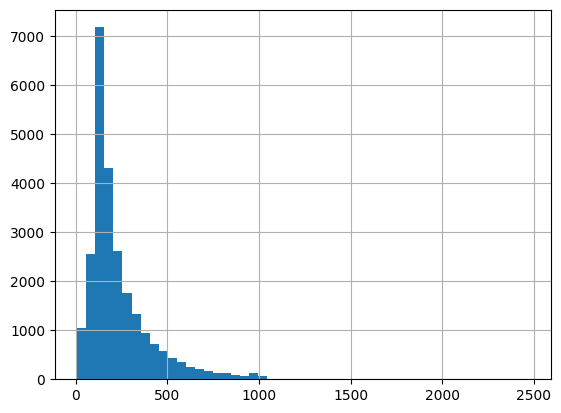

In [ ]:
# Simple EDA: review length distribution
train["n_words"] = train["text"].str.split().str.len()
print(train["n_words"].describe())
train["n_words"].hist(bins=50)

## Part 2: Classical baseline (TF-IDF + Logistic Regression)

In [ ]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report

def clean(t):
    t = re.sub(r"<[^>]+>", " ", t).lower()      # strip HTML like <br />
    return re.sub(r"\s+", " ", t).strip()      # keep punctuation + negations on purpose

X_train = train["text"].map(clean); y_train = train["label"]
X_test = test["text"].map(clean);   y_test = test["label"]

results = {}
for name, clf in {"logreg": LogisticRegression(max_iter=1000, C=4.0),
                  "linear_svm": LinearSVC(C=0.5)}.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=3, max_df=0.9, sublinear_tf=True)),
                     ("clf", clf)])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    results[name] = (accuracy_score(y_test, preds), f1_score(y_test, preds), pipe)
    print(name, "acc=%.4f f1=%.4f" % results[name][:2])

logreg acc=0.9053 f1=0.9054
linear_svm acc=0.9068 f1=0.9068


In [ ]:
# What did the model learn? (Logistic Regression coefficients)
pipe = results["logreg"][2]
names = pipe.named_steps["tfidf"].get_feature_names_out()
coefs = pipe.named_steps["clf"].coef_[0]
order = coefs.argsort()
print("NEGATIVE:", [names[i] for i in order[:20]])
print("POSITIVE:", [names[i] for i in order[-20:]])

NEGATIVE: ['bad', 'worst', 'awful', 'the worst', 'boring', 'poor', 'waste', 'terrible', 'nothing', 'worse', 'no', 'poorly', 'dull', 'horrible', 'stupid', 'unfortunately', 'annoying', 'disappointing', 'disappointment', 'mess']
POSITIVE: ['highly', 'bit', 'beautiful', 'enjoyed', 'enjoyable', 'well', 'brilliant', 'favorite', 'superb', 'loved', 'love', 'today', 'fun', 'best', 'the best', 'amazing', 'wonderful', 'perfect', 'excellent', 'great']


In [ ]:
# Error analysis starter: read the mistakes (this is the most valuable habit here)
preds = results["logreg"][2].predict(X_test)
errors = test[preds != y_test].copy()
errors["pred"] = preds[preds != y_test]
for _, r in errors.sample(5, random_state=0).iterrows():
    print("TRUE:", r["label"], "PRED:", r["pred"])
    print(r["text"][:400], "...\n")

TRUE: 1 PRED: 0
yes barney is nonsense now but when i was a kid it made perfect sense.<br /><br />i haven't gotten any smarter but i enjoyed it. as a child i was mocked because no one could say my name so i changed it. ever since i was 4 I've gone by the name Tina from barney because i could relate to her being from a different culture. i'm 17 now and barney is a huge part of my life . ...my name came from it.... ...

TRUE: 0 PRED: 1
You could see the final outcome from a mile away.All the signs were there....the prom,the liquor,the fast ride,the distraction of the females.... A good commercial for seatbelt usage,and later model vehicles that sit the passengers further back from the windshield.Also,the ending is rather anti climatic,as the Ford Econoline van barely suffers a crease across its nose after hitting a bridge abuttm ...

TRUE: 1 PRED: 0
Visconti's Death in Venice qualifies as one of the most beautiful films ever made. While watching, we acknowledge we are in the hands of a v

## Part 3: Fine-tune DistilBERT (needs GPU runtime)
Takes roughly 15-25 minutes on a free T4.

In [ ]:
import numpy as np, torch
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

print("GPU available:", torch.cuda.is_available())
ckpt = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(ckpt)

def tokenize(batch):
    return tok(batch["text"], truncation=True, max_length=256)

tokenized = ds.map(tokenize, batched=True)
model = AutoModelForSequenceClassification.from_pretrained(ckpt, num_labels=2)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p), "f1": f1_score(labels, p)}

args = TrainingArguments(
    output_dir="distilbert-imdb",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    fp16=torch.cuda.is_available(),
    report_to="none",
)
trainer = Trainer(model=model, args=args,
                  train_dataset=tokenized["train"], eval_dataset=tokenized["test"],
                  data_collator=DataCollatorWithPadding(tok),
                  compute_metrics=compute_metrics)
trainer.train()
print(trainer.evaluate())

GPU available: True


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.258974,0.273238,0.890720,0.882837
2,0.163808,0.275336,0.912320,0.913229


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.163808,0.275336,2,0.912320,0.913229


{'eval_loss': 0.2753359377384186, 'eval_accuracy': 0.91232, 'eval_f1': 0.9132293563454992}


In [ ]:
# Save the model so the Streamlit app can use it later
trainer.save_model("distilbert-imdb-final"); tok.save_pretrained("distilbert-imdb-final")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('distilbert-imdb-final/tokenizer_config.json',
 'distilbert-imdb-final/tokenizer.json')

In [ ]:
# Paste each "# %% CELL" block into its own new cell in the SAME Colab notebook
# (the session that still has `results`, `model`, `tok`, `test`, etc. in memory).

# %% CELL 1: SAVE YOUR MODEL FIRST (Colab wipes files when the runtime resets)
import shutil
from google.colab import drive
drive.mount("/content/drive")
shutil.copytree("distilbert-imdb-final", "/content/drive/MyDrive/wheeltrix_sentiment/distilbert-imdb-final",
                dirs_exist_ok=True)
import joblib
joblib.dump(results["logreg"][2], "/content/drive/MyDrive/wheeltrix_sentiment/logreg_pipeline.joblib")
print("Saved to Google Drive")

Mounted at /content/drive
Saved to Google Drive


In [ ]:
# %% CELL 2: prediction helpers for both models (returns P(positive))
import numpy as np, torch, pandas as pd

lr_pipe = results["logreg"][2]

def lr_probs(texts):
    return lr_pipe.predict_proba([clean(t) for t in texts])[:, 1]

def bert_probs(texts, bs=64):
    model.eval()
    dev = next(model.parameters()).device
    out = []
    for i in range(0, len(texts), bs):
        enc = tok(list(texts[i:i+bs]), truncation=True, max_length=256,
                  padding=True, return_tensors="pt").to(dev)
        with torch.no_grad():
            logits = model(**enc).logits
        out.append(torch.softmax(logits, -1)[:, 1].cpu().numpy())
    return np.concatenate(out)

In [ ]:
# %% CELL 3: behavioral stress-test suite (1 = positive, 0 = negative)
cases = [
    # negation
    ("This movie was not good.", 0, "negation"),
    ("I didn't hate it at all, quite the opposite.", 1, "negation"),
    ("Not bad, not bad at all.", 1, "negation"),
    ("The film is never boring.", 1, "negation"),
    ("I can't say I enjoyed a single minute.", 0, "negation"),
    ("It wasn't a waste of time.", 1, "negation"),
    # sarcasm
    ("Oh great, another two hours of my life I'll never get back.", 0, "sarcasm"),
    ("Wow, what a masterpiece... if you enjoy watching paint dry.", 0, "sarcasm"),
    ("Sure, because plot holes are exactly what I look for in a film.", 0, "sarcasm"),
    ("Brilliant. I loved falling asleep halfway through.", 0, "sarcasm"),
    ("Fantastic, the acting is so wooden it could be used as furniture.", 0, "sarcasm"),
    # mixed (clear overall lean)
    ("Great acting and a wonderful score, though the ending was a bit rushed.", 1, "mixed"),
    ("The visuals are stunning, yet the script is lazy, the pacing is dead and the characters are boring.", 0, "mixed"),
    ("Despite a slow start, it turns into a moving and unforgettable film.", 1, "mixed"),
    ("Some good jokes, but overall a tedious and forgettable comedy.", 0, "mixed"),
    # typos / informal
    ("this movie was awsome, loved evry second", 1, "typos"),
    ("worst film evr, total wast of time", 0, "typos"),
    ("gr8 movie!!! must watch", 1, "typos"),
    ("borrrring and way too long", 0, "typos"),
    ("LOVED IT!!! 10/10", 1, "typos"),
    # very short
    ("A masterpiece.", 1, "short"),
    ("Unwatchable.", 0, "short"),
    ("I loved it.", 1, "short"),
    ("I hated it.", 0, "short"),
    # straightforward
    ("The plot kept me on the edge of my seat until the very last scene.", 1, "straightforward"),
    ("The dialogue was cringe-worthy and the plot made no sense.", 0, "straightforward"),
    ("A heartfelt story with superb performances from the entire cast.", 1, "straightforward"),
    ("A dull, predictable mess with terrible acting.", 0, "straightforward"),
]
suite = pd.DataFrame(cases, columns=["text", "label", "category"])
suite["p_logreg"] = lr_probs(suite["text"])
suite["p_bert"] = bert_probs(suite["text"].tolist())
suite["ok_logreg"] = (suite["p_logreg"] > 0.5).astype(int) == suite["label"]
suite["ok_bert"] = (suite["p_bert"] > 0.5).astype(int) == suite["label"]

print("Accuracy by category:")
print(suite.groupby("category")[["ok_logreg", "ok_bert"]].mean().round(2))
print("\nOverall:", suite[["ok_logreg", "ok_bert"]].mean().round(3).to_dict())

pd.set_option("display.max_colwidth", 90)
print("\nCases where at least one model failed:")
print(suite[~(suite.ok_logreg & suite.ok_bert)][["text", "label", "p_logreg", "p_bert"]].round(2))

Accuracy by category:
                 ok_logreg  ok_bert
category                           
mixed                 1.00     1.00
negation              0.17     0.33
sarcasm               0.60     0.20
short                 1.00     1.00
straightforward       1.00     0.75
typos                 1.00     1.00

Overall: {'ok_logreg': 0.75, 'ok_bert': 0.679}

Cases where at least one model failed:
                                                                  text  label  \
1                         I didn't hate it at all, quite the opposite.      1   
2                                             Not bad, not bad at all.      1   
3                                            The film is never boring.      1   
4                               I can't say I enjoyed a single minute.      0   
5                                           It wasn't a waste of time.      1   
6          Oh great, another two hours of my life I'll never get back.      0   
7          Wow, what a masterpiece.

In [ ]:
# %% CELL 4: domain shift. Models trained on IMDB, tested on other movie-review sources
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score

shift_sets = {
    "IMDB (in-domain)": (test["text"].tolist(), test["label"].tolist()),
}
rt = load_dataset("cornell-movie-review-data/rotten_tomatoes", split="test")   # short snippets
shift_sets["Rotten Tomatoes"] = (rt["text"], rt["label"])
sst = load_dataset("nyu-mll/glue", "sst2", split="validation")                  # short sentences
shift_sets["SST-2"] = (sst["sentence"], sst["label"])

rows = []
for name, (texts, labels) in shift_sets.items():
    texts = list(texts)
    for model_name, fn in [("logreg", lr_probs), ("distilbert", bert_probs)]:
        pred = (fn(texts) > 0.5).astype(int)
        rows.append({"dataset": name, "model": model_name,
                     "accuracy": accuracy_score(labels, pred), "f1": f1_score(labels, pred)})
shift_df = pd.DataFrame(rows).round(4)
print(shift_df.pivot(index="dataset", columns="model", values="accuracy"))
shift_df.to_csv("/content/drive/MyDrive/wheeltrix_sentiment/domain_shift_results.csv", index=False)

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

...

sst2/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

model             distilbert  logreg
dataset                             
IMDB (in-domain)      0.9123  0.9053
Rotten Tomatoes       0.8002  0.7664
SST-2                 0.8624  0.7867


In [ ]:
# %% CELL 1: larger, templated negation suite (100 cases) + confidence intervals
import numpy as np, pandas as pd

pos_adj = ["good", "great", "funny", "enjoyable", "interesting",
           "entertaining", "brilliant", "moving", "impressive", "exciting"]
neg_adj = ["bad", "boring", "terrible", "dull", "awful",
           "disappointing", "weak", "tedious", "annoying", "forgettable"]
neg_templates = ["The movie was not {}.", "I did not find the film {}.",
                 "The story isn't {} at all.", "The acting was never {}."]

rows = []
for a in pos_adj:
    for t in neg_templates:
        rows.append((t.format(a), 0, "negated positive"))      # "not good" -> negative
    rows.append((f"The movie was {a}.", 1, "control (plain positive)"))
for a in neg_adj:
    for t in neg_templates:
        rows.append((t.format(a), 1, "negated negative"))      # "not bad" -> positive
    rows.append((f"The movie was {a}.", 0, "control (plain negative)"))

neg_suite = pd.DataFrame(rows, columns=["text", "label", "group"])
neg_suite["ok_logreg"] = ((lr_probs(neg_suite["text"]) > 0.5).astype(int) == neg_suite["label"])
neg_suite["ok_bert"] = ((bert_probs(neg_suite["text"].tolist()) > 0.5).astype(int) == neg_suite["label"])

def boot_ci(ok, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    ok = np.asarray(ok, dtype=float)
    means = [rng.choice(ok, len(ok)).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

out = []
for g, d in neg_suite.groupby("group"):
    for m in ["ok_logreg", "ok_bert"]:
        lo, hi = boot_ci(d[m])
        out.append({"group": g, "model": m[3:], "n": len(d),
                    "accuracy": d[m].mean(), "ci95": f"[{lo:.2f}, {hi:.2f}]"})
print(pd.DataFrame(out).round(2).to_string(index=False))

                   group  model  n  accuracy         ci95
control (plain negative) logreg 10      1.00 [1.00, 1.00]
control (plain negative)   bert 10      1.00 [1.00, 1.00]
control (plain positive) logreg 10      0.50 [0.20, 0.80]
control (plain positive)   bert 10      1.00 [1.00, 1.00]
        negated negative logreg 40      0.00 [0.00, 0.00]
        negated negative   bert 40      0.60 [0.45, 0.75]
        negated positive logreg 40      0.68 [0.53, 0.82]
        negated positive   bert 40      1.00 [1.00, 1.00]


In [ ]:
# %% CELL 2: is the BERT-vs-logreg gap in domain shift statistically real? (paired bootstrap)
def paired_boot_diff(ok_a, ok_b, n=5000, seed=0):
    rng = np.random.default_rng(seed)
    ok_a, ok_b = np.asarray(ok_a, float), np.asarray(ok_b, float)
    idx = np.arange(len(ok_a))
    diffs = []
    for _ in range(n):
        s = rng.choice(idx, len(idx))
        diffs.append(ok_a[s].mean() - ok_b[s].mean())
    return np.mean(diffs), np.percentile(diffs, [2.5, 97.5])

for name, (texts, labels) in shift_sets.items():
    texts, labels = list(texts), np.asarray(labels)
    ok_b = ((bert_probs(texts) > 0.5).astype(int) == labels)
    ok_l = ((lr_probs(texts) > 0.5).astype(int) == labels)
    d, (lo, hi) = paired_boot_diff(ok_b, ok_l)
    print(f"{name:18s} BERT - logreg = {d*100:+.1f} pts   95% CI [{lo*100:+.1f}, {hi*100:+.1f}]")

IMDB (in-domain)   BERT - logreg = +0.7 pts   95% CI [+0.3, +1.1]
Rotten Tomatoes    BERT - logreg = +3.4 pts   95% CI [+0.5, +6.3]
SST-2              BERT - logreg = +7.6 pts   95% CI [+4.8, +10.3]


In [ ]:
# %% CELL 3: explain individual failures with LIME
!pip install -q lime

from lime.lime_text import LimeTextExplainer
explainer = LimeTextExplainer(class_names=["negative", "positive"])

def bert_proba2(texts):
    p = bert_probs(list(texts))
    return np.vstack([1 - p, p]).T

def lr_proba2(texts):
    p = lr_probs(list(texts))
    return np.vstack([1 - p, p]).T

hard_cases = [
    "Fantastic, the acting is so wooden it could be used as furniture.",   # BERT wrong, logreg right
    "Not bad, not bad at all.",                                            # logreg wrong (0.03)
    "The plot kept me on the edge of my seat until the very last scene.",  # BERT wrong
]
for text in hard_cases:
    for name, fn in [("distilbert", bert_proba2), ("logreg", lr_proba2)]:
        exp = explainer.explain_instance(text, fn, num_features=8, num_samples=500)
        print(f"\n[{name}] {text}")
        print("  P(positive) = %.2f" % fn([text])[0][1])
        print("  word weights:", [(w, round(v, 2)) for w, v in exp.as_list()])
        exp.save_to_file(f"lime_{name}_{abs(hash(text)) % 10000}.html")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 8.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done

[distilbert] Fantastic, the acting is so wooden it could be used as furniture.
  P(positive) = 0.98
  word weights: [(np.str_('Fantastic'), 0.64), (np.str_('wooden'), -0.05), (np.str_('furniture'), 0.04), (np.str_('acting'), -0.03), (np.str_('is'), -0.02), (np.str_('it'), -0.01), (np.str_('as'), 0.01), (np.str_('so'), 0.01)]

[logreg] Fantastic, the acting is so wooden it could be used as furniture.
  P(positive) = 0.21
  word weights: [(np.str_('Fantastic'), 0.25), (np.str_('wooden'), -0.22), (np.str_('acting'), -0.12), (np.str_('is'), -0.12), (np.str_('so'), -0.04), (np.str_('could'), -0.04), (np.str_('it'), 0.03), (np.str_('be'), -0.03)]

[distilbert] Not bad, not bad at all.
  P(positive) = 0.35
  word weights: [(np.str_('Not'), 0.1), (np.str_('not'), 0.09), (np.str_('all'), -0.08), (np.str_('at'), -0.06), (np.str_('bad'), 0.02)]

[logreg] Not bad, not bad at a

In [ ]:
# Paste into a new cell in the SAME Colab notebook.
# Needs: X_train, y_train, X_test, y_test, clean(), results, suite, neg_suite,
# lr_probs/bert_probs helpers, lr_pipe from earlier cells.

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

# Keep negation words IN the vocabulary even though they're normally
# treated as stopwords — they're exactly what the negation stress test needs.
NEGATION_WORDS = {
    "no", "not", "nor", "none", "never", "neither",
    "n't", "cannot", "without", "nothing", "nowhere",
}
custom_stopwords = sorted(ENGLISH_STOP_WORDS - NEGATION_WORDS)

configs = {
    "original (no stopwords, C=4.0)": dict(stop_words=None, C=4.0),
    "stopwords removed, C=4.0": dict(stop_words=custom_stopwords, C=4.0),
    "stopwords removed, C=1.0 (more regularized)": dict(stop_words=custom_stopwords, C=1.0),
}

fitted = {}
rows = []
for name, cfg in configs.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9,
                                  sublinear_tf=True, stop_words=cfg["stop_words"])),
        ("clf", LogisticRegression(max_iter=1000, C=cfg["C"])),
    ])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    preds = pipe.predict(X_test)
    acc, f1 = accuracy_score(y_test, preds), f1_score(y_test, preds)

    def probs(texts, p=pipe):
        return p.predict_proba([clean(t) for t in texts])[:, 1]
    stress_acc = ((probs(suite["text"]) > 0.5).astype(int) == suite["label"]).mean()
    neg_acc = ((probs(neg_suite["text"]) > 0.5).astype(int) == neg_suite["label"]).mean()

    rows.append({"config": name, "test_acc": round(acc, 4), "test_f1": round(f1, 4),
                "stress_suite_acc": round(stress_acc, 3), "negation_suite_acc": round(neg_acc, 3)})

import pandas as pd
comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

# Specifically check "i hate it"
for name, pipe in fitted.items():
    p = pipe.predict_proba([clean("i hate it")])[0, 1]
    print(f"{name:45s} P(positive)=\"i hate it\" = {p:.3f}")

# Peek at top positive/negative words for the fixed model
fixed = fitted["stopwords removed, C=1.0 (more regularized)"]
names = fixed.named_steps["tfidf"].get_feature_names_out()
coefs = fixed.named_steps["clf"].coef_[0]
order = coefs.argsort()
print("\nNEGATIVE:", [names[i] for i in order[:15]])
print("POSITIVE:", [names[i] for i in order[-15:]])

                                     config  test_acc  test_f1  stress_suite_acc  negation_suite_acc
             original (no stopwords, C=4.0)    0.9053   0.9054             0.750                0.42
                   stopwords removed, C=4.0    0.8943   0.8943             0.821                0.36
stopwords removed, C=1.0 (more regularized)    0.8907   0.8911             0.750                0.39
original (no stopwords, C=4.0)                P(positive)="i hate it" = 0.678
stopwords removed, C=4.0                      P(positive)="i hate it" = 0.625
stopwords removed, C=1.0 (more regularized)   P(positive)="i hate it" = 0.548

NEGATIVE: ['worst', 'bad', 'awful', 'boring', 'waste', 'poor', 'nothing', 'no', 'terrible', 'worse', 'dull', 'horrible', 'poorly', 'unfortunately', 'stupid']
POSITIVE: ['superb', 'enjoyed', 'brilliant', 'beautiful', 'today', 'loved', 'fun', 'favorite', 'love', 'amazing', 'wonderful', 'perfect', 'best', 'excellent', 'great']


In [ ]:
# Paste each "# %% CELL" block into its own new cell in the SAME Colab notebook.
# Needs from earlier cells: results, X_train, y_train, X_test, y_test, clean,
# suite, neg_suite, shift_sets (domain-shift cell).

# %% CELL 1: DIAGNOSTIC. Why is "i hate it" positive? Check, don't guess.
import numpy as np
orig = results["logreg"][2]
vec, clf = orig.named_steps["tfidf"], orig.named_steps["clf"]
vocab = vec.vocabulary_

print("Intercept (bias):", round(float(clf.intercept_[0]), 3))
for w in ["hate", "it", "i", "ew", "meh", "lol", "terrible"]:
    if w in vocab:
        print(f"  coef[{w!r}] = {clf.coef_[0][vocab[w]]:+.3f}")
    else:
        print(f"  {w!r}: NOT in vocabulary (model never saw it)")

# How short are the IMDB training reviews, really?
lens = X_train.str.split().str.len()
print("\nIMDB train review length (words): min", lens.min(),
      "| 5th pct", int(lens.quantile(0.05)), "| median", int(lens.median()))
print("Share of train reviews under 20 words: %.2f%%" % (100 * (lens < 20).mean()))


# %% CELL 2: Fix A, negation marking. "not good" -> "not NOT_good" so the model
# gets a separate feature for negated words (classic Das & Chen 2001 trick).
import re

PUNCT = set(".,!?;:")
def mark_negation(text, scope=3):
    text = re.sub(r"n't\b", " not", text)
    toks = re.findall(r"[a-z']+|[.,!?;:]", text)
    out, remaining = [], 0
    for t in toks:
        if t in PUNCT:
            remaining = 0
            out.append(t)
        elif t in {"not", "no", "never", "cannot", "without", "nothing", "neither", "nor"}:
            out.append(t)
            remaining = scope
        elif remaining > 0:
            out.append("NOT_" + t)
            remaining -= 1
        else:
            out.append(t)
    return " ".join(out)

print(mark_negation("this movie was not good, but i didn't hate it."))


# %% CELL 3: Fix B, short-text augmentation. IMDB reviews are long, so short inputs
# are out of distribution. Add Rotten Tomatoes TRAIN snippets (short) to training.
# NOTE: SST-2 and Rotten Tomatoes come from the same source snippets, so once we
# train on RT, SST-2 is no longer a clean held-out set. We evaluate on RT TEST only.
from datasets import load_dataset
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

rt_train = load_dataset("cornell-movie-review-data/rotten_tomatoes", split="train")
rt_test = load_dataset("cornell-movie-review-data/rotten_tomatoes", split="test")

imdb_tr = list(X_train); imdb_y = list(y_train)
rt_tr = [clean(t) for t in rt_train["text"]]; rt_y = list(rt_train["label"])

def build(neg_marking, use_rt):
    texts = imdb_tr + (rt_tr if use_rt else [])
    labels = imdb_y + (rt_y if use_rt else [])
    prep = mark_negation if neg_marking else (lambda t: t)
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)),
        ("clf", LogisticRegression(max_iter=1000, C=4.0)),
    ])
    pipe.fit([prep(t) for t in texts], labels)
    return pipe, prep

configs = {
    "A. original (IMDB only)":           (False, False),
    "B. + negation marking":             (True,  False),
    "C. + Rotten Tomatoes train":        (False, True),
    "D. + negation marking + RT train":  (True,  True),
}

probe = ["i hate it", "ew", "meh", "not bad, not bad at all.", "this movie was not good."]
rows, fitted2 = [], {}
for name, (nm, rt) in configs.items():
    pipe, prep = build(nm, rt)
    fitted2[name] = (pipe, prep)
    P = lambda texts: pipe.predict_proba([prep(clean(t)) for t in texts])[:, 1]
    imdb_acc = accuracy_score(y_test, (P(X_test.tolist()) > 0.5).astype(int))
    rt_acc = accuracy_score(rt_test["label"], (P(rt_test["text"]) > 0.5).astype(int))
    stress = ((P(suite["text"]) > 0.5).astype(int) == suite["label"]).mean()
    neg = ((P(neg_suite["text"]) > 0.5).astype(int) == neg_suite["label"]).mean()
    rows.append({"config": name, "imdb_test": round(imdb_acc, 4), "rt_test": round(rt_acc, 4),
                 "stress_28": round(stress, 3), "negation_100": round(neg, 3),
                 **{f"P({p[:12]})": round(float(v), 2) for p, v in zip(probe, P(probe))}})

print(pd.DataFrame(rows).to_string(index=False))

Intercept (bias): 0.037
  coef['hate'] = -0.039
  coef['it'] = +2.454
  'i': NOT in vocabulary (model never saw it)
  'ew': NOT in vocabulary (model never saw it)
  coef['meh'] = -0.069
  coef['lol'] = +1.104
  coef['terrible'] = -6.930

IMDB train review length (words): min 10 | 5th pct 63 | median 173
Share of train reviews under 20 words: 0.05%
this movie was not NOT_good , but i did not NOT_hate NOT_it .
                          config  imdb_test  rt_test  stress_28  negation_100  P(i hate it)  P(ew)  P(meh)  P(not bad, not)  P(this movie w)
         A. original (IMDB only)     0.9053   0.7664      0.750          0.42          0.68   0.51    0.49             0.03             0.05
           B. + negation marking     0.9082   0.7692      0.821          0.56          0.73   0.51    0.49             0.19             0.02
      C. + Rotten Tomatoes train     0.9065   0.8180      0.786          0.44          0.58   0.44    0.42             0.07             0.03
D. + negation marking + 

In [ ]:
# Paste into a new cell in the SAME Colab notebook (needs `fitted2`, `clean`,
# `neg_suite`, `train` from the earlier cells; re-run cell 3 of file 05 if the
# session restarted).

import os, joblib
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")

# ---- 1. Per-group negation accuracy: where did the +14 points come from? ----
rows = []
for name in ["A. original (IMDB only)", "D. + negation marking + RT train"]:
    pipe, prep = fitted2[name]
    p = pipe.predict_proba([prep(clean(t)) for t in neg_suite["text"]])[:, 1]
    ok = (p > 0.5).astype(int) == neg_suite["label"].values
    g = pd.Series(ok).groupby(neg_suite["group"].values).mean().round(2)
    rows.append(g.rename(name))
print(pd.concat(rows, axis=1).to_string())

# ---- 2. Is "hate" actually uninformative in IMDB? ----
has_hate = train["text"].str.lower().str.contains(r"\bhate\b")
print("\nReviews containing 'hate':", int(has_hate.sum()),
      "| share labelled positive: %.2f" % train.loc[has_hate, "label"].mean())

# ---- 3. Save config D for the app ----
out_dir = "/content/drive/MyDrive/wheeltrix_sentiment"
os.makedirs(out_dir, exist_ok=True)
pipe_d, _ = fitted2["D. + negation marking + RT train"]
joblib.dump(pipe_d, f"{out_dir}/logreg_negation_pipeline.joblib")
print("\nSaved:", f"{out_dir}/logreg_negation_pipeline.joblib")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
                          A. original (IMDB only)  D. + negation marking + RT train
control (plain negative)                     1.00                               1.0
control (plain positive)                     0.50                               0.6
negated negative                             0.00                               0.0
negated positive                             0.68                               1.0

Reviews containing 'hate': 696 | share labelled positive: 0.43

Saved: /content/drive/MyDrive/wheeltrix_sentiment/logreg_negation_pipeline.joblib


In [ ]:
#ERROR TAXONOMY
# %% CELL 1: collect the model's mistakes and export 100 of them to label
import re, joblib, numpy as np, pandas as pd, torch
from datasets import load_dataset
from google.colab import drive
from transformers import AutoTokenizer, AutoModelForSequenceClassification

drive.mount("/content/drive")
DRIVE = "/content/drive/MyDrive/wheeltrix_sentiment"
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)  # if this says cpu, switch the runtime to T4 GPU or this will be slow

tok = AutoTokenizer.from_pretrained(f"{DRIVE}/distilbert-imdb-final")
model = AutoModelForSequenceClassification.from_pretrained(f"{DRIVE}/distilbert-imdb-final").to(dev).eval()

test = pd.DataFrame(load_dataset("stanfordnlp/imdb", split="test"))
texts = test["text"].tolist()

probs, bs = [], 64
with torch.no_grad():
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i + bs], truncation=True, max_length=256, padding=True,
                  return_tensors="pt").to(dev)
        probs.append(torch.softmax(model(**enc).logits, -1)[:, 1].cpu().numpy())
test["p_pos"] = np.concatenate(probs)
test["pred"] = (test["p_pos"] > 0.5).astype(int)
print("accuracy: %.4f  (should be about 0.913)" % (test["pred"] == test["label"]).mean())

errors = test[test["pred"] != test["label"]].copy()
errors["kind"] = np.where(errors["label"] == 1, "false negative (true pos, said neg)",
                          "false positive (true neg, said pos)")
errors["confidence_in_wrong_answer"] = np.where(errors["pred"] == 1, errors["p_pos"],
                                                1 - errors["p_pos"]).round(3)
print(len(errors), "mistakes in total")
print(errors["kind"].value_counts())

# ---- 100 mistakes, chosen at random with a fixed seed so the sample is reproducible ----
sample = errors.sample(n=100, random_state=0).copy()
sample["review_id"] = sample.index
sample["text_full"] = sample["text"].str.replace(r"<br\s*/?>", " ", regex=True)

# What the model never saw: everything after its 256-token cut-off.
def never_saw(t):
    enc = tok(t, truncation=True, max_length=256, return_offsets_mapping=True)
    cut = enc["offset_mapping"][-2][1]  # end of the last kept word piece
    return t[cut:].strip()
sample["model_never_saw"] = sample["text_full"].apply(never_saw)
sample["truncated"] = sample["model_never_saw"].str.len() > 0

# Hint: lots of strongly positive AND strongly negative words -> maybe mixed sentiment.
# The word lists come from the first logistic regression's biggest coefficients.
lr = joblib.load(f"{DRIVE}/logreg_pipeline.joblib")
names = lr.named_steps["tfidf"].get_feature_names_out()
coefs = lr.named_steps["clf"].coef_[0]
uni = sorted([(n, c) for n, c in zip(names, coefs) if " " not in n], key=lambda x: x[1])
neg_words, pos_words = {n for n, _ in uni[:300]}, {n for n, _ in uni[-300:]}
count = lambda t, V: sum(w in V for w in re.findall(r"[a-z']+", t.lower()))
sample["hint_mixed"] = [(count(t, pos_words) >= 4 and count(t, neg_words) >= 4) for t in sample["text_full"]]

sample["text_end"] = sample["text_full"].str[-500:]
sample["text_start"] = sample["text_full"].str[:500]
sample["category"] = ""
sample["notes"] = ""

cols = ["review_id", "kind", "confidence_in_wrong_answer", "truncated", "hint_mixed",
        "model_never_saw", "text_end", "text_start", "text_full", "category", "notes"]
sample[cols].to_csv(f"{DRIVE}/error_sample_to_label.csv", index=False)
print("Saved", f"{DRIVE}/error_sample_to_label.csv")
print("Truncated reviews in the sample:", int(sample["truncated"].sum()))
print("Very confident mistakes (>= 0.95), worth checking for label noise:",
      int((sample["confidence_in_wrong_answer"] >= 0.95).sum()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

accuracy: 0.9124  (should be about 0.913)
2191 mistakes in total
kind
false positive (true neg, said pos)    1226
false negative (true pos, said neg)     965
Name: count, dtype: int64
Saved /content/drive/MyDrive/wheeltrix_sentiment/error_sample_to_label.csv
Truncated reviews in the sample: 55
Very confident mistakes (>= 0.95), worth checking for label noise: 47


Mounted at /content/drive
                             count  percent  95% CI
category                                           
Label noise / ambiguous         24     24.0  17-33%
Mixed sentiment                 25     25.0  18-34%
Negation                         8      8.0   4-15%
Sarcasm / irony                 12     12.0   7-20%
Truncated (verdict cut off)     17     17.0  11-26%
Subject vs. opinion             10     10.0   6-17%
Other                            4      4.0   2-10%

By error direction:
kind                         false negative (true pos, said neg)  \
category                                                           
Label noise / ambiguous                                       12   
Mixed sentiment                                               11   
Negation                                                       5   
Other                                                          0   
Sarcasm / irony                                                4   
Subject v

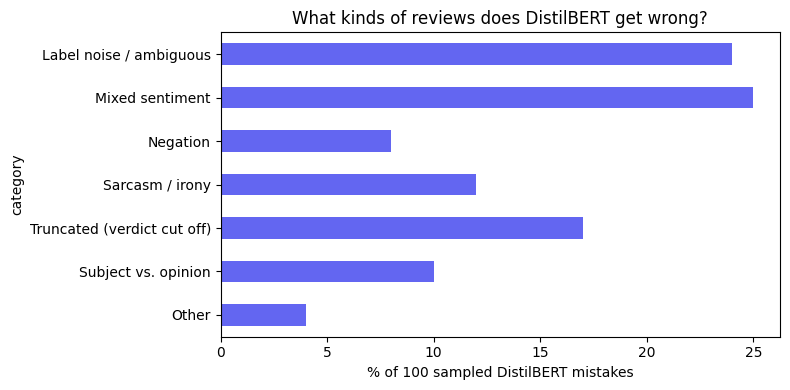


[Label noise / ambiguous] review 15550: ... Amy at a a young age. Matt falls in love with Amy & tries to straighten out his life for her. Very predictable ending. The actress that plays "Amy" is actually 33 years old trying to play a teenager!

[Label noise / ambiguous] review 15131: ...eason 3, and on season 4 they can't show anything from PRUE because she owns the rights of it "PRUE", so the producers would have to pay her for whatever they show. this is the last episode she is in!

[Mixed sentiment] review 12794: ...lternate titles (including "Beyond the Living" and "Hospital of Terror") than any other Adamson movie) is actually fairly entertaining low-budget fare. I ended up having a good time watching it.  7/10

[Mixed sentiment] review 1455: ... ended up as the victory that decided the outcome of Pontiac's War thanks to the wiles of the same Colonel Bouquet who certainly must rank as one of the most successful British commanders of this war.

[Negation] review 19230: ...inning a

In [1]:
# %% CELL 2: run this AFTER you have labelled the sheet and re-uploaded it to Drive
# as error_sample_labeled.csv (File > Download > .csv in Google Sheets, then upload to
# MyDrive/wheeltrix_sentiment/).
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
drive.mount("/content/drive")   # harmless if already mounted; needed after a restart
DRIVE = "/content/drive/MyDrive/wheeltrix_sentiment"

CATS = ["Label noise / ambiguous", "Mixed sentiment", "Negation", "Sarcasm / irony",
        "Truncated (verdict cut off)", "Subject vs. opinion", "Other"]

lab = pd.read_csv(f"{DRIVE}/error_sample_labeled.csv")
# Forgive differences in capitalisation, spaces and punctuation, e.g.
# "Sarcasm/Irony" and "Sarcasm / irony" both map to the canonical name.
_norm = lambda s: re.sub(r"[^a-z]", "", str(s).lower())
_canon = {_norm(c): c for c in CATS}
lab["category"] = lab["category"].map(lambda s: _canon.get(_norm(s), str(s).strip()))
bad = lab[~lab["category"].isin(CATS)]
if len(bad):
    print("These rows have a missing or misspelled category, fix them in the sheet:",
          bad["review_id"].tolist())

def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z * z / n
    c = p + z * z / (2 * n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - h) / d, (c + h) / d

counts = lab["category"].value_counts().reindex(CATS).fillna(0).astype(int)
n = int(counts.sum())
table = pd.DataFrame({"count": counts, "percent": (100 * counts / n).round(1)})
table["95% CI"] = [f"{100*wilson(k, n)[0]:.0f}-{100*wilson(k, n)[1]:.0f}%" for k in counts]
print(table.to_string())
print("\nBy error direction:")
print(pd.crosstab(lab["category"], lab["kind"]))

fig, ax = plt.subplots(figsize=(8, 4))
table["percent"][::-1].plot.barh(ax=ax, color="#6366f1")
ax.set_xlabel("% of 100 sampled DistilBERT mistakes")
ax.set_title("What kinds of reviews does DistilBERT get wrong?")
plt.tight_layout()
plt.savefig(f"{DRIVE}/error_taxonomy.png", dpi=150)
plt.show()

# Short examples for the README (read them before you paste anything public)
for c in CATS:
    ex = lab[lab["category"] == c].head(2)
    for _, r in ex.iterrows():
        print(f"\n[{c}] review {r['review_id']}: ...{str(r['text_end'])[-200:]}")

In [3]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
P = "/content/drive/MyDrive/wheeltrix_sentiment/distilbert-imdb-final"
repo = "sidratahseen/distilbert-imdb-sentiment"
AutoModelForSequenceClassification.from_pretrained(P).push_to_hub(repo)
AutoTokenizer.from_pretrained(P).push_to_hub(repo)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...u3hmd2b/model.safetensors:   0%|          |  574kB /  268MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

CommitInfo(commit_url='https://huggingface.co/sidratahseen/distilbert-imdb-sentiment/commit/9eda8ec6d708dd79812a36d6e68f406649054f57', commit_message='Upload tokenizer', commit_description='', oid='9eda8ec6d708dd79812a36d6e68f406649054f57', pr_url=None, repo_url=RepoUrl('https://huggingface.co/sidratahseen/distilbert-imdb-sentiment', endpoint='https://huggingface.co', repo_type='model', repo_id='sidratahseen/distilbert-imdb-sentiment'), pr_revision=None, pr_num=None)

In [4]:
import sklearn;
print(sklearn.__version__)

1.6.1
